# 25. XGBoost: matched rolling three-day trajectory comparison

Same585 ZIPs,243 daily origins (April30–December28 2020),60-calendar-day training windows,14 within-window warmup days, weekly refits anchored April29. All34 epidemiological/calendar candidates retained, including bothPressure. ZIP identity is native categorical, not a numeric ordered feature or an FE coefficient. No additional static features. Three direct models, horizons1/2/3. Fixed200-tree depth3 settings, no validation-based tuning or early stopping.2021–2023 not run. Existing retrospective cohort/feature development means results remain exploratory.

Reference Dynamic Panel predictions are read from Notebook24 output, never regenerated or changed. Parameter/maturity logs must match. Histories update through each origin; training targets must be <=fit date. Future targets are raw onset counts, not smoothed means.

If XGBoost is not installed, run `%pip install xgboost==3.4.1` once in a separate cell and restart the kernel. Model files use UBJSON to preserve categorical metadata. Documentation: https://xgboost.readthedocs.io/en/stable/python/python_api.html

In [26]:
%pip install xgboost==3.4.1

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Note: you may need to restart the kernel to use updated packages.


In [27]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
GROUPS={
 'core_history':['cases_today','cases_lag_1','cases_lag_7','cases_lag_14'],
 'rolling_level':['cases_mean_7d','cases_mean_14d'],
 'volatility':['case_std_7d','case_std_14d'],
 'dynamics':['case_acceleration','case_jerk'],
 'local_rates':['case_rate_today_per_100k','case_rate_7d_per_100k','case_rate_14d_per_100k'],
 'sparse_history':['days_since_last_observed_case_censored','no_previous_observed_case'],
 'pressure':['nj_covid_pressure_7d','nj_covid_pressure_14d'],
 'month':[f'target_month_{k}' for k in range(2,13)],
 'weekday':[f'target_weekday_{k}' for k in range(2,8)]}

def run_xgboost60(source, cohort_file, output, stage='development', evaluation_plan_frozen=False):
    if stage not in ['development','evaluation']: raise ValueError('Unknown stage')
    if stage=='evaluation' and not evaluation_plan_frozen:
        raise ValueError('Freeze model/features/hyperparameters before running subsequent evaluation.')
    from xgboost import XGBRegressor
    import xgboost, platform
    params=dict(objective='reg:squarederror',tree_method='hist',n_estimators=200,
                max_depth=3,learning_rate=0.05,min_child_weight=20,subsample=0.8,
                colsample_bytree=1.0,reg_lambda=5.0,reg_alpha=0.0,max_bin=128,
                enable_categorical=True,max_cat_to_onehot=4,max_cat_threshold=64,
                random_state=20261027,n_jobs=4)
    source,output=Path(source),Path(output)
    output.mkdir(parents=True,exist_ok=True)
    with source.open('rb') as f:
        if f.read(7)==b'version': raise ValueError('Input is a Git LFS pointer. Download the real gzip data first.')
    models=output/'models';models.mkdir(exist_ok=True)
    importance=[]
    ids=pd.read_csv(cohort_file,dtype={'zip':str})['zip'].to_numpy(dtype='U5')
    numeric=sum([v for k,v in GROUPS.items() if k not in ['month','weekday','sparse_history']],[])
    cols=['zip','date','pressure_definition']+numeric
    frame=pd.read_csv(source,usecols=cols,dtype={'zip':str},parse_dates=['date'])
    dates=pd.date_range('2020-03-01','2023-12-31')
    frame=frame.loc[frame.zip.isin(ids)&frame.date.isin(dates)]
    assert len(ids)==585 and not frame.duplicated(['zip','date']).any()
    assert frame.pressure_definition.eq('valid_population_nj_origins_renormalized_v2').all()
    arrays={c:frame.pivot(index='zip',columns='date',values=c).reindex(index=ids,columns=dates).to_numpy(float) for c in numeric}
    counts=arrays['cases_today'];features=sum(GROUPS.values(),[])
    assert np.isfinite(counts).all() and (counts>=0).all()
    # End-of-day origins: initial fit includes mature targets through April29.
    # A 60-day interval includes14 warmup days, leaving45/44/43 pairs per ZIP.
    first=int(dates.get_loc('2020-04-29'))
    origin_start='2020-04-30' if stage=='development' else '2021-01-01'
    origin_end='2020-12-28' if stage=='development' else '2023-12-28'
    origins=np.flatnonzero((dates>=origin_start)&(dates<=origin_end))
    actual=np.stack([counts[:,origins+h] for h in (1,2,3)],axis=2)
    pred=np.full_like(actual,np.nan);logs=[];coefficients=[];omitted=[]
    # Anchor weekly schedule to April29, keep same schedule across stage boundaries.
    fit_indices=np.unique(first+7*((origins-first)//7))
    for fit in fit_indices:
        lo=fit-59
        batch=np.flatnonzero((origins>=fit)&(origins<fit+7))
        assert lo>=0 and len(batch)>0
        last=np.full(len(ids),-1,dtype=int)
        gap=np.empty((len(ids),len(dates)));never=np.empty_like(gap)
        gap[:]=np.nan;never[:]=np.nan
        for t in range(lo,max(fit,int(origins[batch[-1]]))+1):
            last=np.where(counts[:,t]>0,t,last)
            never[:,t]=(last<0);gap[:,t]=np.where(last>=0,t-last,t-lo+1)
        arrays['no_previous_observed_case']=never
        arrays['days_since_last_observed_case_censored']=gap
        for hh,h in enumerate((1,2,3)):
            train=np.arange(lo+14,fit-h+1)
            target=dates+pd.Timedelta(days=h)
            for k in range(2,13): arrays[f'target_month_{k}']=np.broadcast_to((target.month==k).astype(float),counts.shape)
            for k in range(2,8): arrays[f'target_weekday_{k}']=np.broadcast_to((target.dayofweek==k-1).astype(float),counts.shape)
            xt=np.stack([arrays[f][:,train] for f in features],axis=2)
            xp=np.stack([arrays[f][:,origins[batch]] for f in features],axis=2)
            yt=counts[:,train+h]
            assert np.isfinite(xt).all() and np.isfinite(xp).all()
            assert train[0]-14>=lo and train[-1]+h<=fit and np.all(origins[batch]+h>fit)
            # Same34 epidemiologic/calendar columns, plus native categorical ZIP
            # to represent identity without treating postal numbers as ordered.
            def design(values):
                d=pd.DataFrame(values.reshape(-1,len(features)),columns=features)
                d['region_id']=pd.Categorical(np.repeat(ids,values.shape[1]),categories=ids)
                return d
            train_x,predict_x=design(xt),design(xp)
            model=XGBRegressor(**params)
            model.fit(train_x,yt.ravel()) # no validation scores / early stopping
            pred[:,batch,hh]=model.predict(predict_x).reshape(len(ids),len(batch))
            model.save_model(models/f'xgb_{dates[fit].date()}_h{h}.ubj')
            for feature,gain in model.get_booster().get_score(importance_type='gain').items():
                importance.append(dict(fit_date=str(dates[fit].date()),horizon=h,feature=feature,training_split_gain=float(gain)))
            logs.append(dict(fit_date=str(dates[fit].date()),window_start=str(dates[lo].date()),window_end=str(dates[fit].date()),window_calendar_days=60,horizon=h,training_origin_start=str(dates[train[0]].date()),training_origin_end=str(dates[train[-1]].date()),latest_training_target=str(dates[train[-1]+h].date()),usable_training_origins=len(train),forecast_origin_start=str(dates[origins[batch[0]]].date()),forecast_origin_end=str(dates[origins[batch[-1]]].date()),candidate_columns=len(features),model_input_columns=len(features)+1,estimator="XGBoost",boosting_rounds=params["n_estimators"]))
        print('Completed fit:',dates[fit].date(),flush=True)
    assert np.isfinite(pred).all()
    np.savez_compressed(output/'predictions.npz',raw_predictions=pred,actual_cases=actual,zip=ids,forecast_origins=dates[origins].to_numpy(),horizons=[1,2,3])
    pd.DataFrame(logs).to_csv(output/'training_timing.csv',index=False)
    pd.DataFrame(importance).to_csv(output/'training_split_gain.csv',index=False)
    (output/'model_parameters.json').write_text(json.dumps(dict(parameters=params,xgboost_version=xgboost.__version__,python_version=platform.python_version(),tuning='None; fixed before viewing this run',region_identity='Native categorical ZIP, same region identity available to FE benchmark. Not numeric postal ordering.',static_attributes='Not added; matched34-column candidate information set'),indent=2),encoding='utf8')
    pd.DataFrame([(g,f) for g,fs in GROUPS.items() for f in fs],columns=['group','feature']).to_csv(output/'candidate_features.csv',index=False)
    p=np.maximum(pred,0);err=p-actual;da=np.diff(actual,axis=2);dp=np.diff(p,axis=2)
    aa=np.diff(actual,n=2,axis=2)[...,0];ap=np.diff(p,n=2,axis=2)[...,0]
    daily=pd.DataFrame(dict(forecast_origin=dates[origins],trajectory_MAE=np.abs(err).mean(axis=(0,2)),MSE=(err**2).mean(axis=(0,2)),mean_bias=err.mean(axis=(0,2)),slope_MAE=np.abs((p[...,2]-p[...,0]-actual[...,2]+actual[...,0])/2).mean(axis=0),direction_agreement=(np.sign(p[...,2]-p[...,0])==np.sign(actual[...,2]-actual[...,0])).mean(axis=0),two_step_shape_agreement=(np.sign(dp)==np.sign(da)).all(axis=2).mean(axis=0),change_MAE=np.abs(dp-da).mean(axis=(0,2)),acceleration_MAE=np.abs(ap-aa).mean(axis=0),all_zero_actual_path_share=(actual==0).all(axis=2).mean(axis=0)))
    daily.to_csv(output/'scores_by_forecast_origin.csv',index=False)
    rows=[]
    periods={'overall':np.repeat('all',len(daily)),'year':daily.forecast_origin.dt.year.astype(str).to_numpy(),'quarter':daily.forecast_origin.dt.to_period('Q').astype(str).to_numpy()}
    for scope,values in periods.items():
        for label in np.unique(values):
            d=daily.loc[values==label];r=dict(scope=scope,period=label,forecast_origins=len(d),regions=len(ids),paths=len(d)*len(ids),RMSE=float(np.sqrt(d.MSE.mean())))
            r.update({col:float(d[col].mean()) for col in daily.columns if col not in ['forecast_origin','MSE']});rows.append(r)
    scores=pd.DataFrame(rows);scores.to_csv(output/'trajectory_scores_by_period.csv',index=False)
    protocol=dict(stage=stage,initial_training=['2020-03-01','2020-04-29'],development=['2020-04-30','2020-12-31'],evaluation=['2021-01-01','2023-12-31'],window_calendar_days=60,retrain_every_days=7,first_fit='2020-04-29 end of day',prediction='Daily end-of-day origin predicts t+1,t+2,t+3; raw onset counts',boundaries='All3 targets remain within stage; development origins end Dec28 2020, evaluation origins end Dec28 2023. December29-31 origins omitted to avoid crossing targets.',maturity='Every training target <=fit date; forecast targets >forecast origin>=fit date',feature_policy='Same34 candidates including bothPressure plus native categorical ZIP. No new static attributes, no feature selection. Training-only tree splits; no early stopping on validation.',warmup='14 days inside each60-day window,45/44/43 usable training origins per ZIP per horizon; sparse-history state reset at window start',inputs='Updated daily through origin; coefficients updated only on anchored7-day schedule',evaluation_policy='Algorithm and settings frozen before subsequent-period run. Past realized evaluation labels may enter future scheduled fits; no retrospective prediction changes or manual tuning.',limitation='Exploratory retrospective time evaluation;2021-2023 previously inspected. Onset-date availability assumed, reporting delays not modeled.',source_sha256=hashlib.sha256(source.read_bytes()).hexdigest())
    (output/'protocol.json').write_text(json.dumps(protocol,indent=2),encoding='utf8')
    (output/'verification.json').write_text(json.dumps(dict(all_training_targets_mature=True,window_exactly60=True,forecast_targets_after_fit=True,all_predictions_finite=True,all34_candidates_considered=True,per_zip_metrics_produced=False,no_validation_early_stopping=True),indent=2))
    (output/'RESULTS.md').write_text('# XGBoost rolling60-day trajectory evaluation\n\n'+scores.to_string(index=False)+'\n\n60 calendar days,14 within-window warmup days;45/44/43 supervised origins per horizon per ZIP. Weekly re-estimation, daily predictor updates. No Pressure ablation or seasonal naive. Primary score is ZIP-path trajectory MAE; change/acceleration and direction/shape are supplementary. Scores are retrospective and exploratory. See protocol.json and training_timing.csv for information boundaries. No coefficient p-values or causal feature interpretations are asserted for this XGBoost estimator.\n',encoding='utf8')
    return scores, output


In [28]:
ROOT=Path.cwd()
if not (ROOT/'rolling_trajectory_outputs').exists() and (ROOT/'Weikun').is_dir():
    ROOT=ROOT/'Weikun'
SOURCE=ROOT/'rolling_trajectory_outputs'/'inputs'/'nj_daily_features.csv.gz'
COHORT=ROOT/'fixed60_trajectory_outputs'/'fixed60_20261027'/'common_regions.csv'
BASELINE=ROOT/'rolling_trajectory_outputs'/'rolling60_weekly_development_20261027'
OUTPUT=ROOT/'xgboost_trajectory_outputs'/'xgb60_weekly_development_20261027'
scores,folder=run_xgboost60(SOURCE,COHORT,OUTPUT,stage='development')
display(scores)
print('Saved to:',folder.resolve())

Completed fit: 2020-04-29
Completed fit: 2020-05-06
Completed fit: 2020-05-13
Completed fit: 2020-05-20
Completed fit: 2020-05-27
Completed fit: 2020-06-03
Completed fit: 2020-06-10
Completed fit: 2020-06-17
Completed fit: 2020-06-24
Completed fit: 2020-07-01
Completed fit: 2020-07-08
Completed fit: 2020-07-15
Completed fit: 2020-07-22
Completed fit: 2020-07-29
Completed fit: 2020-08-05
Completed fit: 2020-08-12
Completed fit: 2020-08-19
Completed fit: 2020-08-26
Completed fit: 2020-09-02
Completed fit: 2020-09-09
Completed fit: 2020-09-16
Completed fit: 2020-09-23
Completed fit: 2020-09-30
Completed fit: 2020-10-07
Completed fit: 2020-10-14
Completed fit: 2020-10-21
Completed fit: 2020-10-28
Completed fit: 2020-11-04
Completed fit: 2020-11-11
Completed fit: 2020-11-18
Completed fit: 2020-11-25
Completed fit: 2020-12-02
Completed fit: 2020-12-09
Completed fit: 2020-12-16
Completed fit: 2020-12-23


,scope,period,forecast_origins,regions,paths,RMSE,trajectory_MAE,mean_bias,slope_MAE,direction_agreement,two_step_shape_agreement,change_MAE,acceleration_MAE,all_zero_actual_path_share
0,overall,all,243,585,142155,1.431245,0.754299,0.003984,0.439963,0.227357,0.089951,0.870869,1.548966,0.428145
1,year,2020,243,585,142155,1.431245,0.754299,0.003984,0.439963,0.227357,0.089951,0.870869,1.548966,0.428145
2,quarter,2020Q2,62,585,36270,0.950359,0.476298,0.104595,0.255649,0.167935,0.061180,0.499099,0.903941,0.575903
3,quarter,2020Q3,92,585,53820,0.821850,0.424450,-0.014825,0.235210,0.161464,0.054738,0.460998,0.846753,0.552861
4,quarter,2020Q4,89,585,52065,2.065333,1.288930,-0.046663,0.780015,0.336867,0.146394,1.553541,2.724193,0.196293


Saved to: C:\Users\41240\OneDrive\文档\GitHub\practicum-project\Weikun\xgboost_trajectory_outputs\xgb60_weekly_development_20261027


## Matched model comparison
No seasonal naive, no Pressure ablation, no new feature selection. Both models are scored on identical actual arrays and saved forecasts. Trajectory MAE is primary;RMSE,bias,direction,shape,change and acceleration support interpretation. Block confidence intervals resample common forecast dates for all ZIPs together; overlapping paths are not independent. No unadjusted coefficient p-values are reported. The34-column information set is shared, but model complexity and identity representations differ.

In [29]:
from pathlib import Path
import json,hashlib
import numpy as np
import pandas as pd

def compare_archives(reference, candidate, output):
    reference,candidate,output=Path(reference),Path(candidate),Path(output)
    output.mkdir(parents=True,exist_ok=True)
    with np.load(reference,allow_pickle=False) as r, np.load(candidate,allow_pickle=False) as c:
        for key in ['zip','forecast_origins','horizons','actual_cases']:
            assert np.array_equal(r[key],c[key]),'Mismatched '+key
        a=r['actual_cases'].copy();base=np.maximum(r['raw_predictions'],0);new=np.maximum(c['raw_predictions'],0)
        dates=pd.to_datetime(r['forecast_origins']);h=r['horizons'].copy();ids=r['zip'].copy()
    assert a.shape==(585,243,3) and np.isfinite(new).all()
    rows=[];daily={};group_rows=[];horizon_rows=[]
    true_direction=np.sign(a[...,2]-a[...,0]);true_steps=np.sign(np.diff(a,axis=2));true_acc=np.diff(a,n=2,axis=2)[...,0]
    for name,p in [('Dynamic Panel FE',base),('XGBoost',new)]:
        e=p-a;steps=np.diff(p,axis=2);direction=np.sign(p[...,2]-p[...,0]);acc=np.diff(p,n=2,axis=2)[...,0]
        cm=np.array([[np.sum((true_direction==i)&(direction==j)) for j in [-1,0,1]] for i in [-1,0,1]])
        recall=np.diag(cm)/cm.sum(axis=1)
        row=dict(model=name,trajectory_MAE=np.abs(e).mean(),pooled_RMSE=np.sqrt((e**2).mean()),mean_bias=e.mean(),direction_agreement=(direction==true_direction).mean(),balanced_direction_accuracy=recall.mean(),two_step_shape_agreement=(np.sign(steps)==true_steps).all(axis=2).mean(),change_MAE=np.abs(steps-np.diff(a,axis=2)).mean(),acceleration_MAE=np.abs(acc-true_acc).mean(),change_sign_agreement=(np.sign(steps)==true_steps).mean(),acceleration_sign_agreement=(np.sign(acc)==np.sign(true_acc)).mean())
        rows.append(row)
        pd.DataFrame(cm,index=pd.Index(['Declining','Endpoint-flat','Rising'],name='Actual'),columns=['Declining','Endpoint-flat','Rising']).to_csv(output/f'{"xgboost" if name=="XGBoost" else "dynamic_panel"}_direction_confusion.csv')
        daily[name]=pd.DataFrame(dict(forecast_origin=dates,trajectory_MAE=np.abs(e).mean(axis=(0,2)),MSE=(e**2).mean(axis=(0,2)),mean_bias=e.mean(axis=(0,2)),direction_agreement=(direction==true_direction).mean(axis=0),two_step_shape_agreement=(np.sign(steps)==true_steps).all(axis=2).mean(axis=0),change_MAE=np.abs(steps-np.diff(a,axis=2)).mean(axis=(0,2)),acceleration_MAE=np.abs(acc-true_acc).mean(axis=0)))
        for hh,hhval in enumerate(h):
            er=e[...,hh];horizon_rows.append(dict(model=name,horizon=int(hhval),MAE=np.abs(er).mean(),RMSE=np.sqrt((er**2).mean()),bias=er.mean(),observations=er.size))
        for group,mask in [('all_paths',np.ones(a.shape[:2],bool)),('actual_all_three_zero',(a==0).all(axis=2)),('actual_endpoint_nonflat',true_direction!=0),('actual_endpoint_flat',true_direction==0)]:
            group_rows.append(dict(model=name,subgroup=group,paths=int(mask.sum()),trajectory_MAE=np.abs(e[mask]).mean(),direction_agreement=(direction[mask]==true_direction[mask]).mean(),two_step_shape_agreement=(np.sign(steps[mask])==true_steps[mask]).all(axis=1).mean()))
    pd.DataFrame(rows).to_csv(output/'model_comparison_overall.csv',index=False)
    pd.DataFrame(group_rows).to_csv(output/'matched_subgroup_comparison.csv',index=False)
    pd.DataFrame(horizon_rows).to_csv(output/'horizon_comparison.csv',index=False)
    diffs=pd.DataFrame({'forecast_origin':dates})
    for col in ['trajectory_MAE','direction_agreement','two_step_shape_agreement','change_MAE','acceleration_MAE']:
        diffs[col+'_improvement']=daily['XGBoost'][col]-daily['Dynamic Panel FE'][col] if 'agreement' in col else daily['Dynamic Panel FE'][col]-daily['XGBoost'][col]
    diffs.to_csv(output/'paired_daily_improvements.csv',index=False)
    rng=np.random.default_rng(20261027);intervals=[];T=len(dates)
    for block in [7,14]:
        starts=rng.integers(0,T-block+1,(2000,int(np.ceil(T/block))))
        idx=(starts[...,None]+np.arange(block)).reshape(2000,-1)[:,:T]
        for col in diffs.columns[1:]:
            v=diffs[col].to_numpy();lo,hi=np.quantile(v[idx].mean(axis=1),[.025,.975])
            intervals.append(dict(metric=col,mean_improvement=v.mean(),ci95_low=lo,ci95_high=hi,block_days=block,resamples=2000,interpretation='Positive favors XGBoost; exploratory pointwise date-block interval, not selection-adjusted. All ZIPs resampled together.'))
    pd.DataFrame(intervals).to_csv(output/'paired_date_block_intervals.csv',index=False)
    quarters=[]
    for name,d in daily.items():
        for quarter,frame in d.groupby(d.forecast_origin.dt.to_period('Q')):
            r=dict(model=name,quarter=str(quarter),origins=len(frame),RMSE=np.sqrt(frame.MSE.mean()))
            r.update({col:frame[col].mean() for col in d.columns if col not in ['forecast_origin','MSE']});quarters.append(r)
    pd.DataFrame(quarters).to_csv(output/'matched_quarter_comparison.csv',index=False)
    report='# XGBoost vs Dynamic Panel: matched2020 rolling validation\n\n'+pd.DataFrame(rows).to_string(index=False)+'\n\nBoth models use identical585 ZIPs,243 forecast origins,3 target days,60-calendar-day windows,14 within-window warmup and weekly refit dates. Both include the34 candidate columns and region identity. XGBoost represents ZIP as a native categorical input, not an FE coefficient or ordered ZIP number. Fixed200-tree depth3 configuration; no validation-based tuning/early stopping. This is a comparison of two implementations with different inductive biases, not causal attribution to nonlinearity alone.\n\nPrimary comparison: mean ZIP-path MAE. Positive paired improvement favors XGBoost. Seven-day moving-block intervals are primary descriptive uncertainty,14-day intervals sensitivity; no independent-ZIP assumption, p-values or post-selection claims. Period/cohort were previously explored. Raw-count changes, exact-flat signs and imbalance must be considered. Overall summaries can conceal differences by quarter or path type.\n'
    (output/'RESULTS.md').write_text(report,encoding='utf8')
    (output/'comparison_verification.json').write_text(json.dumps(dict(identical_region_order=True,identical_origin_dates=True,identical_horizons=True,identical_actuals=True,paths=585*243,reference_sha256=hashlib.sha256(reference.read_bytes()).hexdigest(),candidate_sha256=hashlib.sha256(candidate.read_bytes()).hexdigest()),indent=2))
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    colors=['#64748b','#2563eb'];table=pd.DataFrame(rows)
    fig,axes=plt.subplots(1,3,figsize=(13,4))
    for ax,col,title in zip(axes,['trajectory_MAE','direction_agreement','two_step_shape_agreement'],['Trajectory MAE (cases)','Endpoint direction agreement','Two-step shape agreement']):
        bars=ax.bar(['Dynamic Panel','XGBoost'],table[col],color=colors)
        ax.set_title(title);ax.set_ylim(0,float(table[col].max())*1.25);ax.grid(axis='y',alpha=.2)
        ax.bar_label(bars,labels=[f'{v:.1%}' if 'agreement' in col else f'{v:.3f}' for v in table[col]],padding=3)
    fig.suptitle('Matched2020 rolling validation |585 ZIPs |243 daily origins |3-day paths')
    fig.tight_layout();fig.savefig(output/'01_matched_model_comparison.png',dpi=250);plt.close(fig)
    fig,ax=plt.subplots(figsize=(12,4))
    for (name,d),color in zip(daily.items(),colors):ax.plot(dates,d.trajectory_MAE,label=name,color=color,lw=1)
    ax.set(xlabel='Forecast origin',ylabel='Trajectory MAE (cases)',title='Daily matched trajectory error');ax.legend(frameon=False);ax.grid(alpha=.2)
    fig.tight_layout();fig.savefig(output/'02_daily_error_comparison.png',dpi=250);plt.close(fig)
    return pd.DataFrame(rows),pd.DataFrame(intervals)


In [30]:
comparison,intervals=compare_archives(BASELINE/'predictions.npz',OUTPUT/'predictions.npz',OUTPUT/'comparison')
display(comparison)
display(intervals)
display(pd.read_csv(OUTPUT/'comparison'/'matched_quarter_comparison.csv'))
display(pd.read_csv(OUTPUT/'comparison'/'matched_subgroup_comparison.csv'))

,model,trajectory_MAE,pooled_RMSE,mean_bias,direction_agreement,balanced_direction_accuracy,two_step_shape_agreement,change_MAE,acceleration_MAE,change_sign_agreement,acceleration_sign_agreement
0,Dynamic Panel FE,0.774283,1.418396,0.067025,0.281552,0.383913,0.126116,0.896647,1.589743,0.283726,0.313200
1,XGBoost,0.754299,1.431245,0.003984,0.227357,0.348201,0.089951,0.870869,1.548966,0.223457,0.270852


,metric,mean_improvement,ci95_low,ci95_high,block_days,resamples,interpretation
0,trajectory_MAE_improvement,0.019984,0.006662,0.038684,7,2000,Positive favors XGBoost; exploratory pointwise...
1,direction_agreement_improvement,-0.054194,-0.070720,-0.038654,7,2000,Positive favors XGBoost; exploratory pointwise...
2,two_step_shape_agreement_improvement,-0.036165,-0.051846,-0.021152,7,2000,Positive favors XGBoost; exploratory pointwise...
3,change_MAE_improvement,0.025778,0.015418,0.036496,7,2000,Positive favors XGBoost; exploratory pointwise...
4,acceleration_MAE_improvement,0.040777,0.021978,0.061847,7,2000,Positive favors XGBoost; exploratory pointwise...
5,trajectory_MAE_improvement,0.019984,0.004212,0.041696,14,2000,Positive favors XGBoost; exploratory pointwise...
6,direction_agreement_improvement,-0.054194,-0.073160,-0.034220,14,2000,Positive favors XGBoost; exploratory pointwise...
7,two_step_shape_agreement_improvement,-0.036165,-0.053515,-0.016003,14,2000,Positive favors XGBoost; exploratory pointwise...
8,change_MAE_improvement,0.025778,0.012468,0.040308,14,2000,Positive favors XGBoost; exploratory pointwise...
9,acceleration_MAE_improvement,0.040777,0.017042,0.068476,14,2000,Positive favors XGBoost; exploratory pointwise...


,model,quarter,origins,RMSE,trajectory_MAE,mean_bias,direction_agreement,two_step_shape_agreement,change_MAE,acceleration_MAE
0,Dynamic Panel FE,2020Q2,62,1.040407,0.498861,0.118157,0.278991,0.145547,0.565715,1.021620
1,Dynamic Panel FE,2020Q3,92,0.772692,0.426897,0.009563,0.206447,0.089521,0.469918,0.864522
2,Dynamic Panel FE,2020Q4,89,2.030217,1.325246,0.090802,0.360972,0.150408,1.568296,2.735180
3,XGBoost,2020Q2,62,0.950359,0.476298,0.104595,0.167935,0.061180,0.499099,0.903941
4,XGBoost,2020Q3,92,0.821850,0.424450,-0.014825,0.161464,0.054738,0.460998,0.846753
5,XGBoost,2020Q4,89,2.065333,1.288930,-0.046663,0.336867,0.146394,1.553541,2.724193


,model,subgroup,paths,trajectory_MAE,direction_agreement,two_step_shape_agreement
0,Dynamic Panel FE,all_paths,142155,0.774283,0.281552,0.126116
1,Dynamic Panel FE,actual_all_three_zero,60863,0.230589,0.112515,0.076648
2,Dynamic Panel FE,actual_endpoint_nonflat,61441,1.290469,0.530769,0.129653
3,Dynamic Panel FE,actual_endpoint_flat,80714,0.381352,0.091843,0.123423
4,XGBoost,all_paths,142155,0.754299,0.227357,0.089951
5,XGBoost,actual_all_three_zero,60863,0.184631,0.004683,0.003615
6,XGBoost,actual_endpoint_nonflat,61441,1.296568,0.521069,0.119790
7,XGBoost,actual_endpoint_flat,80714,0.341514,0.003779,0.067237


## Residual Moran's I
Use exactly the same spatial weights and permutation definition as Notebook24: geographic8-neighbor symmetric union, row-standardized,999 permutations. K4/K12 descriptive sensitivity. ZIP–ZCTA mapping remains unvalidated. Significance is an exploratory residual-exchangeability diagnostic, not proof of spatial adequacy. MeanI and shares of significant dates do not constitute a direct paired significance test between models.

In [31]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd

def residual_moran(archive, geography, output, permutations=999, seed=20261027):
    """Global residual Moran's I at each origin/horizon, no fitting."""
    archive,geography,output=Path(archive),Path(geography),Path(output)
    output.mkdir(parents=True,exist_ok=True)
    with np.load(archive,allow_pickle=False) as z:
        ids=z['zip'].astype(str);dates=pd.to_datetime(z['forecast_origins']);h=z['horizons']
        residual=np.maximum(z['raw_predictions'],0)-z['actual_cases']
    assert np.array_equal(h,[1,2,3]) and np.isfinite(residual).all()
    g=pd.read_csv(geography,sep='\t',dtype={'GEOID':str});g.columns=g.columns.str.strip()
    g['GEOID']=g.GEOID.str.zfill(5)
    assert not g.GEOID.duplicated().any()
    matched=g.set_index('GEOID').reindex(ids)
    coords=matched[['INTPTLAT','INTPTLONG']].apply(pd.to_numeric,errors='coerce').to_numpy()
    if not np.isfinite(coords).all():raise ValueError('Missing coordinates: do not silently drop regions')
    n,T,H=residual.shape;assert n==len(ids) and len(set(ids))==n
    # Haversine distance, internal representative points, not polygon centroids.
    lat,lon=np.deg2rad(coords).T
    dlat=lat[:,None]-lat;dlon=lon[:,None]-lon
    term=np.sin(dlat/2)**2+np.cos(lat[:,None])*np.cos(lat)*np.sin(dlon/2)**2
    distance=6371.0088*2*np.arcsin(np.sqrt(np.clip(term,0,1)))
    np.fill_diagonal(distance,np.inf)
    order=np.argsort(distance,axis=1,kind='stable') # stable tie-break = saved cohort order
    centered=residual.reshape(n,-1)-residual.reshape(n,-1).mean(axis=0)
    den=(centered**2).sum(axis=0);valid=den>1e-20;expected=-1/(n-1)
    def weights(k):
        binary=np.zeros((n,n),bool);binary[np.arange(n)[:,None],order[:,:k]]=True
        binary|=binary.T;np.fill_diagonal(binary,False)
        w=binary/binary.sum(axis=1)[:,None]
        assert np.allclose(w.sum(axis=1),1) and np.all(np.diag(w)==0)
        return w,binary
    def statistic(z,w):
        # Edge form avoids a new dependency on spatial-statistics packages.
        i,j=np.nonzero(w)
        return (n/w.sum())*np.einsum('e,ec,ec->c',w[i,j],z[i],z[j],optimize=False)/np.where(valid,den,np.nan)
    results=[];sensitivity=[]
    for k in [4,8,12]:
        w,binary=weights(k);observed=statistic(centered,w)
        sensitivity.append(observed)
        if k!=8:continue
        ei,ej=np.nonzero(w);ew=w[ei,ej]
        pd.DataFrame(dict(origin_zip=ids[ei],neighbor_zip=ids[ej],weight=ew,distance_km=distance[ei,ej])).to_csv(output/'spatial_weights_knn8.csv',index=False)
        pd.DataFrame(dict(zip=ids,latitude=coords[:,0],longitude=coords[:,1],neighbor_degree=binary.sum(axis=1),geography_status='exact_identifier_match_unvalidated')).to_csv(output/'geography_alignment.csv',index=False)
        rng=np.random.default_rng(seed);extreme=np.zeros(centered.shape[1],dtype=int)
        # One permutation of region labels for the whole residual cube preserves
        # each region's temporal/horizon profile. Tests remain marginal by date/h.
        for b in range(permutations):
            perm=rng.permutation(n)
            sim=statistic(centered[perm],w)
            extreme+=np.abs(sim-expected)>=np.abs(observed-expected)-1e-14
            if (b+1)%100==0:print(f'Moran permutations: {b+1}/{permutations}',flush=True)
        p=(extreme+1)/(permutations+1);p[~valid]=np.nan
        # BH across all valid origin-horizon tests in THIS stage/run.
        q=np.full_like(p,np.nan);idx=np.flatnonzero(valid);ranked=idx[np.argsort(p[idx])]
        q[ranked]=np.minimum(1,np.minimum.accumulate((p[ranked]*len(idx)/np.arange(1,len(idx)+1))[::-1])[::-1])
        for t,date in enumerate(dates):
            for hh,horizon in enumerate(h):
                c=t*H+hh
                results.append(dict(forecast_origin=str(date.date()),target_date=str((date+pd.Timedelta(days=int(horizon))).date()),horizon=int(horizon),regions=n,Moran_I=observed[c],expected_I=expected,p_permutation_two_sided=p[c],q_BH=q[c],residual_variance=float(den[c]/n),status='ok' if valid[c] else 'undefined_constant_residuals'))
        # Independent dense-form formula check on first valid residual vector.
        c=int(idx[0]);vec=centered[:,c]
        assert np.isclose(observed[c],n/w.sum()*(vec@w@vec)/(vec@vec))
        assert np.allclose(statistic(centered+0,w),statistic(-centered,w),equal_nan=True)
    table=pd.DataFrame(results);table.to_csv(output/'residual_moran_by_origin_horizon.csv',index=False)
    sens=[]
    for k,values in zip([4,8,12],sensitivity):
        for hh,horizon in enumerate(h):
            v=values.reshape(T,H)[:,hh];sens.append(dict(k=k,horizon=int(horizon),mean_Moran_I=float(np.nanmean(v)),median_Moran_I=float(np.nanmedian(v)),positive_I_share=float(np.mean(v>0)),inference='Descriptive sensitivity only; no p-values for alternative k'))
    pd.DataFrame(sens).to_csv(output/'weight_sensitivity.csv',index=False)
    summary=[]
    for scope,labels in [('overall',np.repeat('all',len(table))),('quarter',pd.to_datetime(table.forecast_origin).dt.to_period('Q').astype(str).to_numpy()),('year',pd.to_datetime(table.forecast_origin).dt.year.astype(str).to_numpy())]:
        for label in np.unique(labels):
            for horizon in h:
                d=table.loc[(labels==label)&table.horizon.eq(horizon)&table.status.eq('ok')]
                summary.append(dict(scope=scope,period=label,horizon=int(horizon),valid_tests=len(d),mean_Moran_I=d.Moran_I.mean(),median_Moran_I=d.Moran_I.median(),raw_p_below_05_share=d.p_permutation_two_sided.lt(.05).mean(),BH_q_below_05_share=d.q_BH.lt(.05).mean(),positive_I_and_BH_q_below_05_share=(d.Moran_I.gt(0)&d.q_BH.lt(.05)).mean()))
    summary=pd.DataFrame(summary);summary.to_csv(output/'residual_moran_summary.csv',index=False)
    protocol=dict(metric="Global residual Moran's I",residual='max(raw_prediction,0)-actual; sign convention does not change I',alignment='At each forecast origin and horizon, compare585 ZIP residuals; never flatten region-days or sum across regions',spatial_weights='Symmetric union of8 nearest neighbors using haversine distances between2021 Gazetteer internal points; zero diagonal, row-standardized after symmetrizing. Weights after normalization are not necessarily symmetric.',primary_k=8,sensitivity_k=[4,12],distance='Great-circle km; internal points, not polygon centroid or adjacency',mapping='Exact postal ZIP identifier to ZCTA GEOID remains unvalidated; diagnostic conditional on this mapping',null='Exchangeability of residual labels across regions conditional on fitted predictions; heteroskedastic count residuals may violate it. Exploratory diagnostic, not a formal spatial-regression specification test.',permutations=permutations,seed=seed,p_value='(1+count(|I_perm-EI|>=|I_obs-EI|))/(B+1), two-sided centered atEI=-1/(n-1)',multiple_testing='Benjamini-Hochberg across all valid dates x horizons in this stage; overlapping dates/spatial dependence mean FDR control is not guaranteed. No pooled overall significance claim.',constant_residual_policy='Undefined I and p, retained as NA',parameter_fitting='None. No prediction or feature changes.',inference='Positive I indicates similar signed residuals cluster under selected W. Nonsignificance is not evidence that all spatial patterns are explained.',reference='https://pysal.org/esda/stable/user-guide/global_morans_i.html',archive_sha256=hashlib.sha256(archive.read_bytes()).hexdigest(),geography_sha256=hashlib.sha256(geography.read_bytes()).hexdigest())
    (output/'residual_moran_definition.json').write_text(json.dumps(protocol,indent=2),encoding='utf8')
    (output/'verification.json').write_text(json.dumps(dict(all585_coordinates_present=True,weights_zero_diagonal=True,weights_rows_sum_to_one=True,dense_formula_crosscheck=True,sign_invariance_verified=True,predictions_unchanged=True,tests=len(table)),indent=2))
    report='# Residual spatial autocorrelation: rolling60 weekly model\n\n'+summary.loc[summary.scope.eq('overall')].to_string(index=False)+'\n\nMoran I is computed separately for each origin and horizon. A positive value suggests clustering of similarly signed forecast errors under the chosen geographic weights. Summary means are descriptive; they do not have a pooled p-value. Permutation p-values and BH q-values are exploratory, conditional on the fitted model, residual exchangeability, and unvalidated ZIP-ZCTA identifiers. Count residual magnitudes vary by region; this can affect the interpretation. Nonsignificance does not prove spatial adequacy. K4/K12 are sensitivity checks, not selected by results. No model refit.\n'
    (output/'RESULTS.md').write_text(report,encoding='utf8')
    try:
        import matplotlib
        matplotlib.use('Agg')
        import matplotlib.pyplot as plt
        fig,axes=plt.subplots(3,1,figsize=(12,8),sharex=True)
        for ax,horizon in zip(axes,h):
            d=table.loc[table.horizon.eq(horizon)];x=pd.to_datetime(d.forecast_origin)
            ax.plot(x,d.Moran_I,color='#2563eb',lw=1,label="Residual Moran's I")
            sig=d.q_BH.lt(.05);ax.scatter(x[sig],d.loc[sig,'Moran_I'],s=9,color='#d94841',label='BH q <0.05 (exploratory)')
            ax.axhline(expected,color='#64748b',ls='--',lw=1,label='Randomization expectation')
            ax.set(ylabel="Moran's I",title=f'{horizon}-day ahead');ax.grid(alpha=.2)
        axes[0].legend(frameon=False,ncol=3,fontsize=8);axes[-1].set_xlabel('Forecast origin')
        fig.suptitle('Residual spatial clustering |8-neighbor geographic weights |2020 rolling validation')
        fig.tight_layout();fig.savefig(output/'residual_moran_by_origin.png',dpi=220);plt.close(fig)
    except ImportError:print('Optional plot requires matplotlib')
    return table,summary


In [32]:
moran_daily,moran_summary=residual_moran(OUTPUT/'predictions.npz',ROOT/'rolling_trajectory_outputs'/'inputs'/'2021_Gaz_zcta_national.txt',OUTPUT/'residual_moran')
display(moran_summary.loc[moran_summary.scope.eq('overall')])
spatial=[]
for model,path in [('Dynamic Panel FE',BASELINE/'residual_moran'),('XGBoost',OUTPUT/'residual_moran')]:
    d=pd.read_csv(path/'residual_moran_summary.csv')
    d=d.loc[d.scope.eq('overall')].copy();d.insert(0,'model',model);spatial.append(d)
spatial_comparison=pd.concat(spatial)
spatial_comparison.to_csv(OUTPUT/'comparison'/'residual_moran_comparison.csv',index=False)
display(spatial_comparison)

Moran permutations: 100/999
Moran permutations: 200/999
Moran permutations: 300/999
Moran permutations: 400/999
Moran permutations: 500/999
Moran permutations: 600/999
Moran permutations: 700/999
Moran permutations: 800/999
Moran permutations: 900/999


,scope,period,horizon,valid_tests,mean_Moran_I,median_Moran_I,raw_p_below_05_share,BH_q_below_05_share,positive_I_and_BH_q_below_05_share
0,overall,all,1,243,0.026861,0.019564,0.378601,0.271605,0.263374
1,overall,all,2,243,0.032914,0.025660,0.419753,0.325103,0.320988
2,overall,all,3,243,0.037613,0.029224,0.465021,0.399177,0.395062


,model,scope,period,horizon,valid_tests,mean_Moran_I,median_Moran_I,raw_p_below_05_share,BH_q_below_05_share,positive_I_and_BH_q_below_05_share
0,Dynamic Panel FE,overall,all,1,243,0.025396,0.019898,0.333333,0.246914,0.242798
1,Dynamic Panel FE,overall,all,2,243,0.031826,0.024509,0.403292,0.308642,0.304527
2,Dynamic Panel FE,overall,all,3,243,0.038911,0.031635,0.481481,0.366255,0.362140
0,XGBoost,overall,all,1,243,0.026861,0.019564,0.378601,0.271605,0.263374
1,XGBoost,overall,all,2,243,0.032914,0.025660,0.419753,0.325103,0.320988
2,XGBoost,overall,all,3,243,0.037613,0.029224,0.465021,0.399177,0.395062


## Read saved results without retraining
The files are already calculated. To inspect immediately after opening a fresh kernel, run only the following cell. Run earlier training cells only if you intend to reproduce the experiment. Training split gain is a model diagnostic, not statistical significance, causal importance or feature selection.

,model,trajectory_MAE,pooled_RMSE,mean_bias,direction_agreement,balanced_direction_accuracy,two_step_shape_agreement,change_MAE,acceleration_MAE,change_sign_agreement,acceleration_sign_agreement
0,Dynamic Panel FE,0.774283,1.418396,0.067025,0.281552,0.383913,0.126116,0.896647,1.589743,0.283726,0.313200
1,XGBoost,0.754299,1.431245,0.003984,0.227357,0.348201,0.089951,0.870869,1.548966,0.223457,0.270852


,metric,mean_improvement,ci95_low,ci95_high,block_days,resamples,interpretation
0,trajectory_MAE_improvement,0.019984,0.006662,0.038684,7,2000,Positive favors XGBoost; exploratory pointwise...
1,direction_agreement_improvement,-0.054194,-0.070720,-0.038654,7,2000,Positive favors XGBoost; exploratory pointwise...
2,two_step_shape_agreement_improvement,-0.036165,-0.051846,-0.021152,7,2000,Positive favors XGBoost; exploratory pointwise...
3,change_MAE_improvement,0.025778,0.015418,0.036496,7,2000,Positive favors XGBoost; exploratory pointwise...
4,acceleration_MAE_improvement,0.040777,0.021978,0.061847,7,2000,Positive favors XGBoost; exploratory pointwise...
5,trajectory_MAE_improvement,0.019984,0.004212,0.041696,14,2000,Positive favors XGBoost; exploratory pointwise...
6,direction_agreement_improvement,-0.054194,-0.073160,-0.034220,14,2000,Positive favors XGBoost; exploratory pointwise...
7,two_step_shape_agreement_improvement,-0.036165,-0.053515,-0.016003,14,2000,Positive favors XGBoost; exploratory pointwise...
8,change_MAE_improvement,0.025778,0.012468,0.040308,14,2000,Positive favors XGBoost; exploratory pointwise...
9,acceleration_MAE_improvement,0.040777,0.017042,0.068476,14,2000,Positive favors XGBoost; exploratory pointwise...


,model,scope,period,horizon,valid_tests,mean_Moran_I,median_Moran_I,raw_p_below_05_share,BH_q_below_05_share,positive_I_and_BH_q_below_05_share
0,Dynamic Panel FE,overall,all,1,243,0.025396,0.019898,0.333333,0.246914,0.242798
1,Dynamic Panel FE,overall,all,2,243,0.031826,0.024509,0.403292,0.308642,0.304527
2,Dynamic Panel FE,overall,all,3,243,0.038911,0.031635,0.481481,0.366255,0.362140
3,XGBoost,overall,all,1,243,0.026861,0.019564,0.378601,0.271605,0.263374
4,XGBoost,overall,all,2,243,0.032914,0.025660,0.419753,0.325103,0.320988
5,XGBoost,overall,all,3,243,0.037613,0.029224,0.465021,0.399177,0.395062


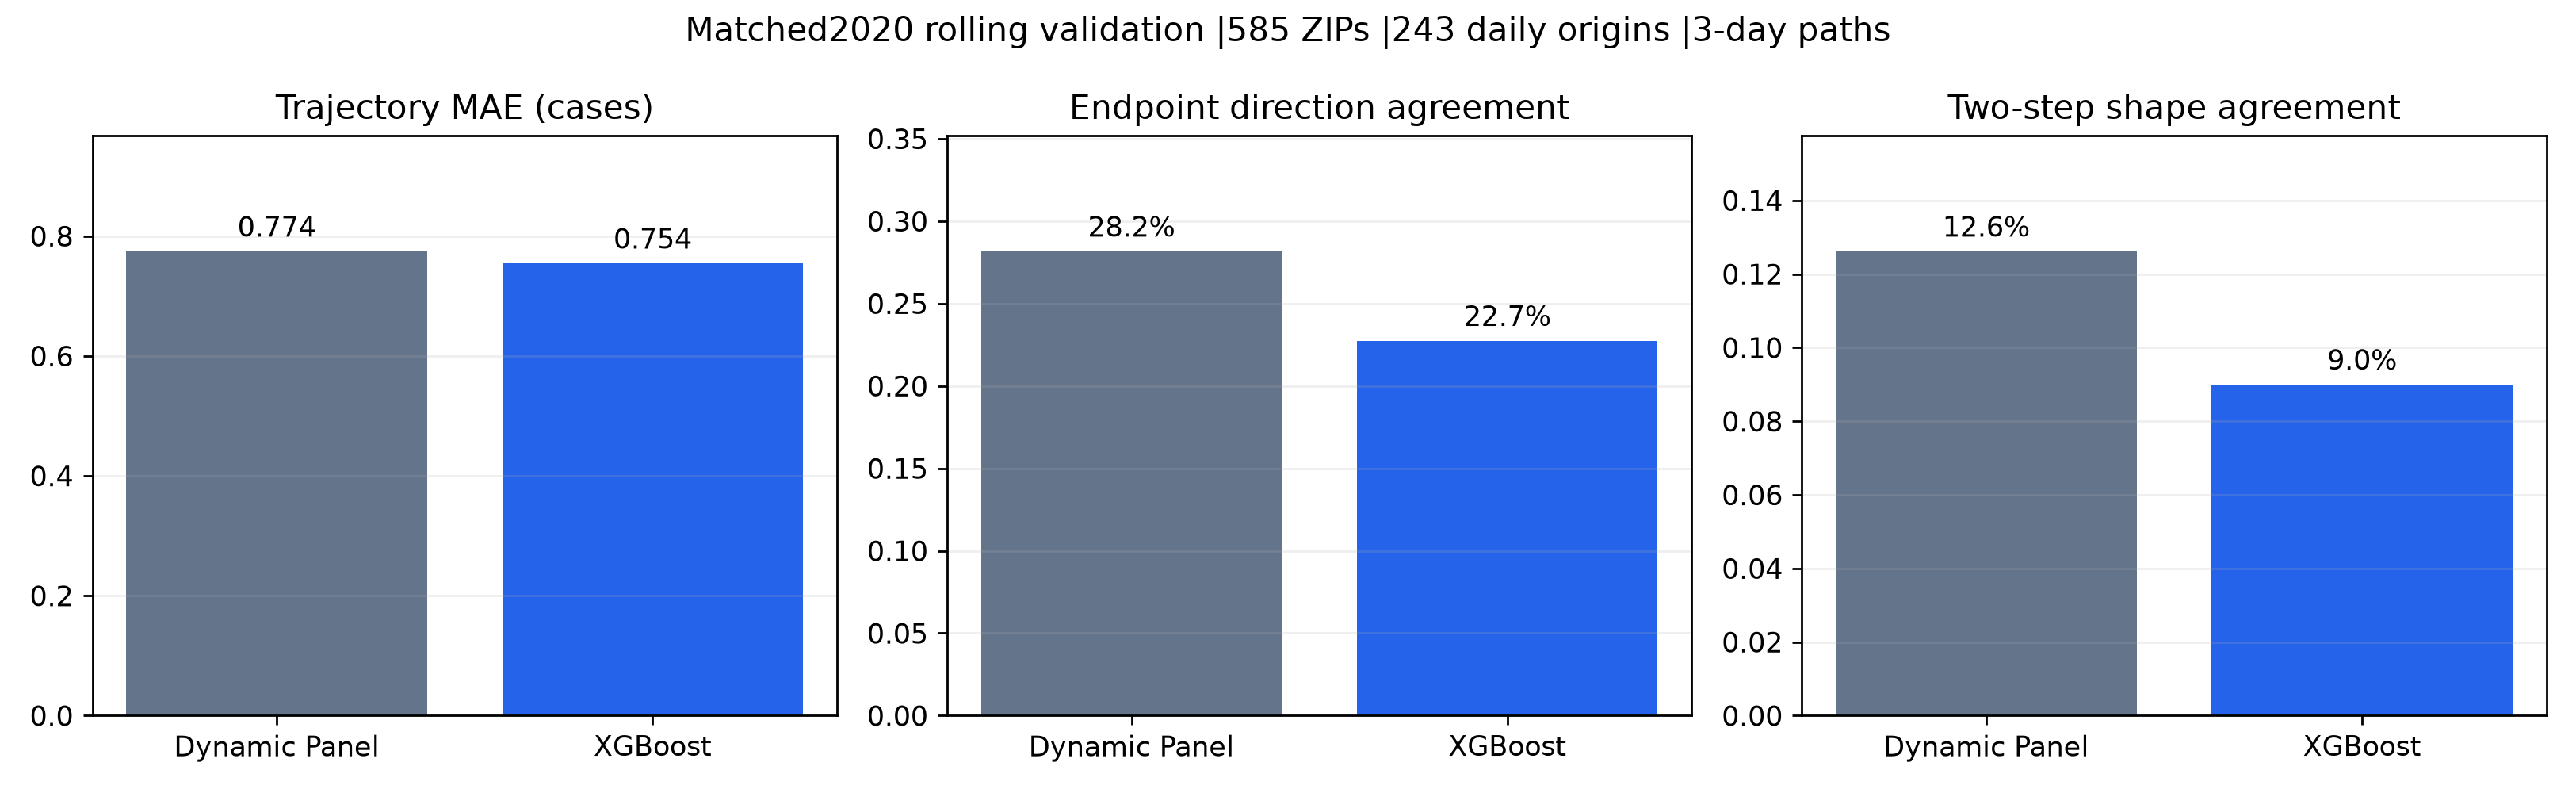

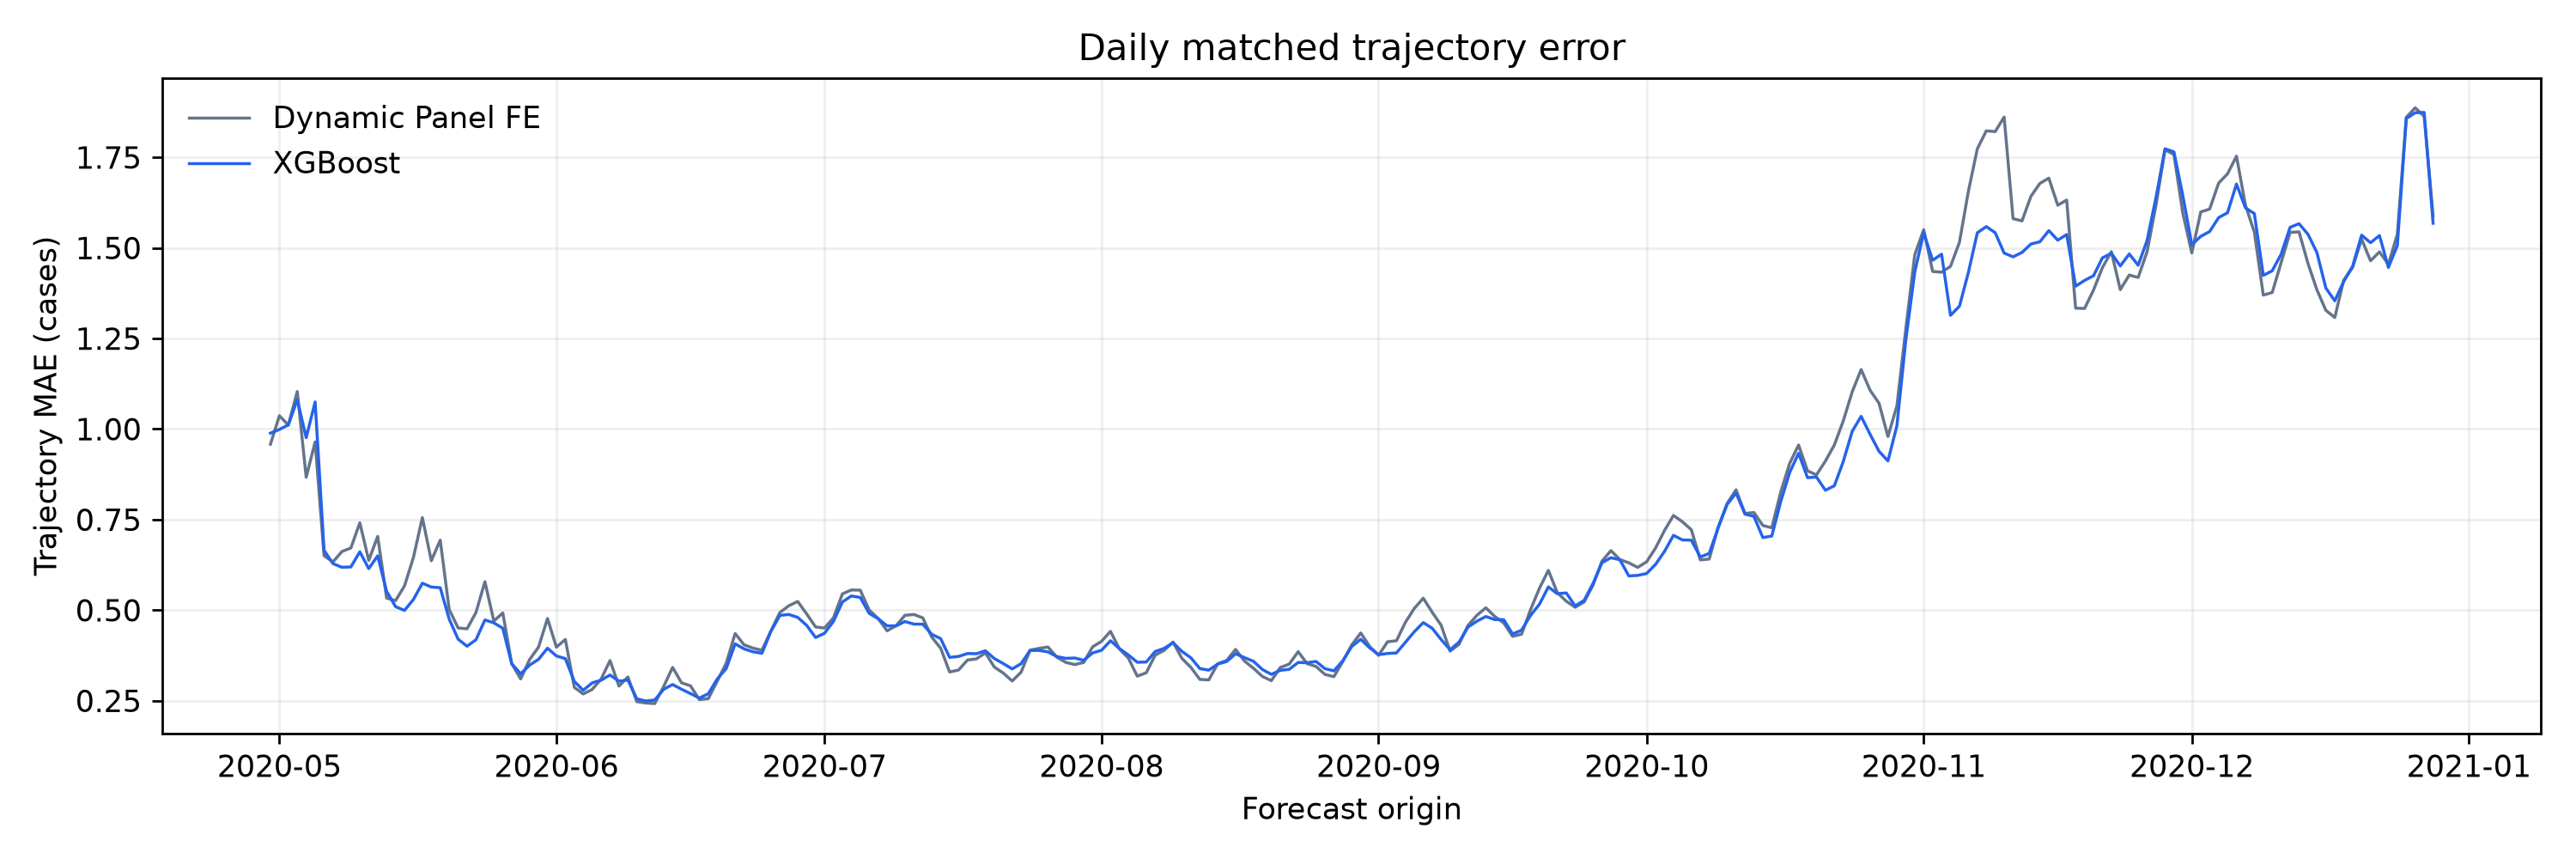

# XGBoost vs Dynamic Panel: matched2020 rolling validation

           model  trajectory_MAE  pooled_RMSE  mean_bias  direction_agreement  balanced_direction_accuracy  two_step_shape_agreement  change_MAE  acceleration_MAE  change_sign_agreement  acceleration_sign_agreement
Dynamic Panel FE        0.774283     1.418396   0.067025             0.281552                     0.383913                  0.126116    0.896647          1.589743               0.283726                     0.313200
         XGBoost        0.754299     1.431245   0.003984             0.227357                     0.348201                  0.089951    0.870869          1.548966               0.223457                     0.270852

Both models use identical585 ZIPs,243 forecast origins,3 target days,60-calendar-day windows,14 within-window warmup and weekly refit dates. Both include the34 candidate columns and region identity. XGBoost represents ZIP as a native categorical input, not an FE coefficient or ordered ZIP numb

In [33]:
from pathlib import Path
import pandas as pd
from IPython.display import Image,display
SAVED_ROOT=Path.cwd()
if not (SAVED_ROOT/'xgboost_trajectory_outputs').exists() and (SAVED_ROOT/'Weikun').is_dir():
    SAVED_ROOT=SAVED_ROOT/'Weikun'
SAVED=SAVED_ROOT/'xgboost_trajectory_outputs'/'xgb60_weekly_development_20261027'
display(pd.read_csv(SAVED/'comparison'/'model_comparison_overall.csv'))
display(pd.read_csv(SAVED/'comparison'/'paired_date_block_intervals.csv'))
display(pd.read_csv(SAVED/'comparison'/'residual_moran_comparison.csv'))
for name in ['01_matched_model_comparison.png','02_daily_error_comparison.png']:
    display(Image(filename=str(SAVED/'comparison'/name)))
print((SAVED/'comparison'/'RESULTS.md').read_text(encoding='utf8'))

## Subsequent evaluation remains off
The model function supports an explicitly frozen evaluation plan, but no2021–2023 run is executed in this notebook. Freeze shared targets/features/settings before proceeding. Later years were inspected previously, so any later evaluation remains retrospective, not untouched testing. No automatic tuning on2020 summary scores.

## Actual and predicted case curves alongside errors

The previous daily plot is an ERROR plot, so actual cases should not be plotted as another error line. The new combined figure keeps MAE in the top panel and adds actual/predicted aggregate counts for each horizon below. X axes are forecast origins; target dates are origin+horizon. Aggregation can hide offsetting regional errors. The separate two-origin illustration shows true three-point same-origin trajectories; dates chosen for early/late illustration, not representative performance. No refit or smoothing.

In [34]:
from pathlib import Path
import numpy as np
import pandas as pd

def plot_actual_and_forecasts(reference,candidate,output):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    output=Path(output);output.mkdir(parents=True,exist_ok=True)
    with np.load(reference,allow_pickle=False) as r,np.load(candidate,allow_pickle=False) as c:
        for key in ['zip','forecast_origins','horizons','actual_cases']:
            assert np.array_equal(r[key],c[key]),'Mismatched '+key
        a=r['actual_cases'];dp=np.maximum(r['raw_predictions'],0);xg=np.maximum(c['raw_predictions'],0)
        dates=pd.to_datetime(r['forecast_origins']);h=r['horizons'];n=len(r['zip'])
    fig,axes=plt.subplots(4,1,figsize=(13,12),sharex=True)
    axes[0].plot(dates,np.abs(dp-a).mean(axis=(0,2)),color='#64748b',label='Dynamic Panel FE')
    axes[0].plot(dates,np.abs(xg-a).mean(axis=(0,2)),color='#2563eb',label='XGBoost')
    axes[0].set(title='Trajectory error: ZIP-level three-day MAE',ylabel='MAE (cases)')
    axes[0].legend(frameon=False,ncol=2)
    export=[]
    for hh,horizon in enumerate(h):
        ax=axes[hh+1]
        for name,values,color in [('Actual',a,'#111827'),('Dynamic Panel FE',dp,'#64748b'),('XGBoost',xg,'#2563eb')]:
            totals=values[...,hh].sum(axis=0)
            ax.plot(dates,totals,color=color,label=name,lw=1.3 if name=='Actual' else 1)
            for date,value in zip(dates,totals):export.append(dict(forecast_origin=date,horizon=int(horizon),target_date=date+pd.Timedelta(days=int(horizon)),series=name,total_cases=float(value)))
        ax.set(title=f'{int(horizon)}-day ahead: actual and predicted counts summed across {n} ZIPs',ylabel='Total daily cases')
        ax.legend(frameon=False,ncol=3)
    for ax in axes:ax.grid(alpha=.2)
    axes[-1].set_xlabel('Forecast origin (target date = origin + horizon)')
    fig.suptitle('2020 rolling validation: forecast errors and actual/predicted case activity',fontsize=15)
    fig.text(.5,.012,'Top: errors averaged over ZIP-level paths. Bottom: aggregate counts, not accuracy scores; regional errors may cancel. No smoothing.',ha='center',fontsize=9)
    fig.tight_layout(rect=[0,.035,1,.97])
    fig.savefig(output/'03_error_and_actual_forecasts.png',dpi=220);plt.close(fig)
    pd.DataFrame(export).to_csv(output/'aggregate_actual_forecasts.csv',index=False)
    # Same-origin three-point paths: two predetermined early/late origins.
    chosen=[dates[0],pd.Timestamp('2020-11-02')]
    fig,axes=plt.subplots(1,2,figsize=(11,4),squeeze=False)
    for ax,date in zip(axes[0],chosen):
        t=dates.get_loc(date)
        for name,values,color in [('Actual',a,'#111827'),('Dynamic Panel FE',dp,'#64748b'),('XGBoost',xg,'#2563eb')]:
            ax.plot(h,values[:,t,:].sum(axis=0),marker='o',label=name,color=color)
        ax.set(title=f'Forecast origin: {date.date()}',xlabel='Days ahead',ylabel=f'Total daily cases across {n} ZIPs',xticks=h)
        ax.legend(frameon=False,fontsize=8);ax.grid(alpha=.2)
    fig.suptitle('Three-day trajectories from the SAME forecast origin: two illustrative dates')
    fig.tight_layout();fig.savefig(output/'04_actual_three_day_path_examples.png',dpi=240);plt.close(fig)
    return output/'03_error_and_actual_forecasts.png'


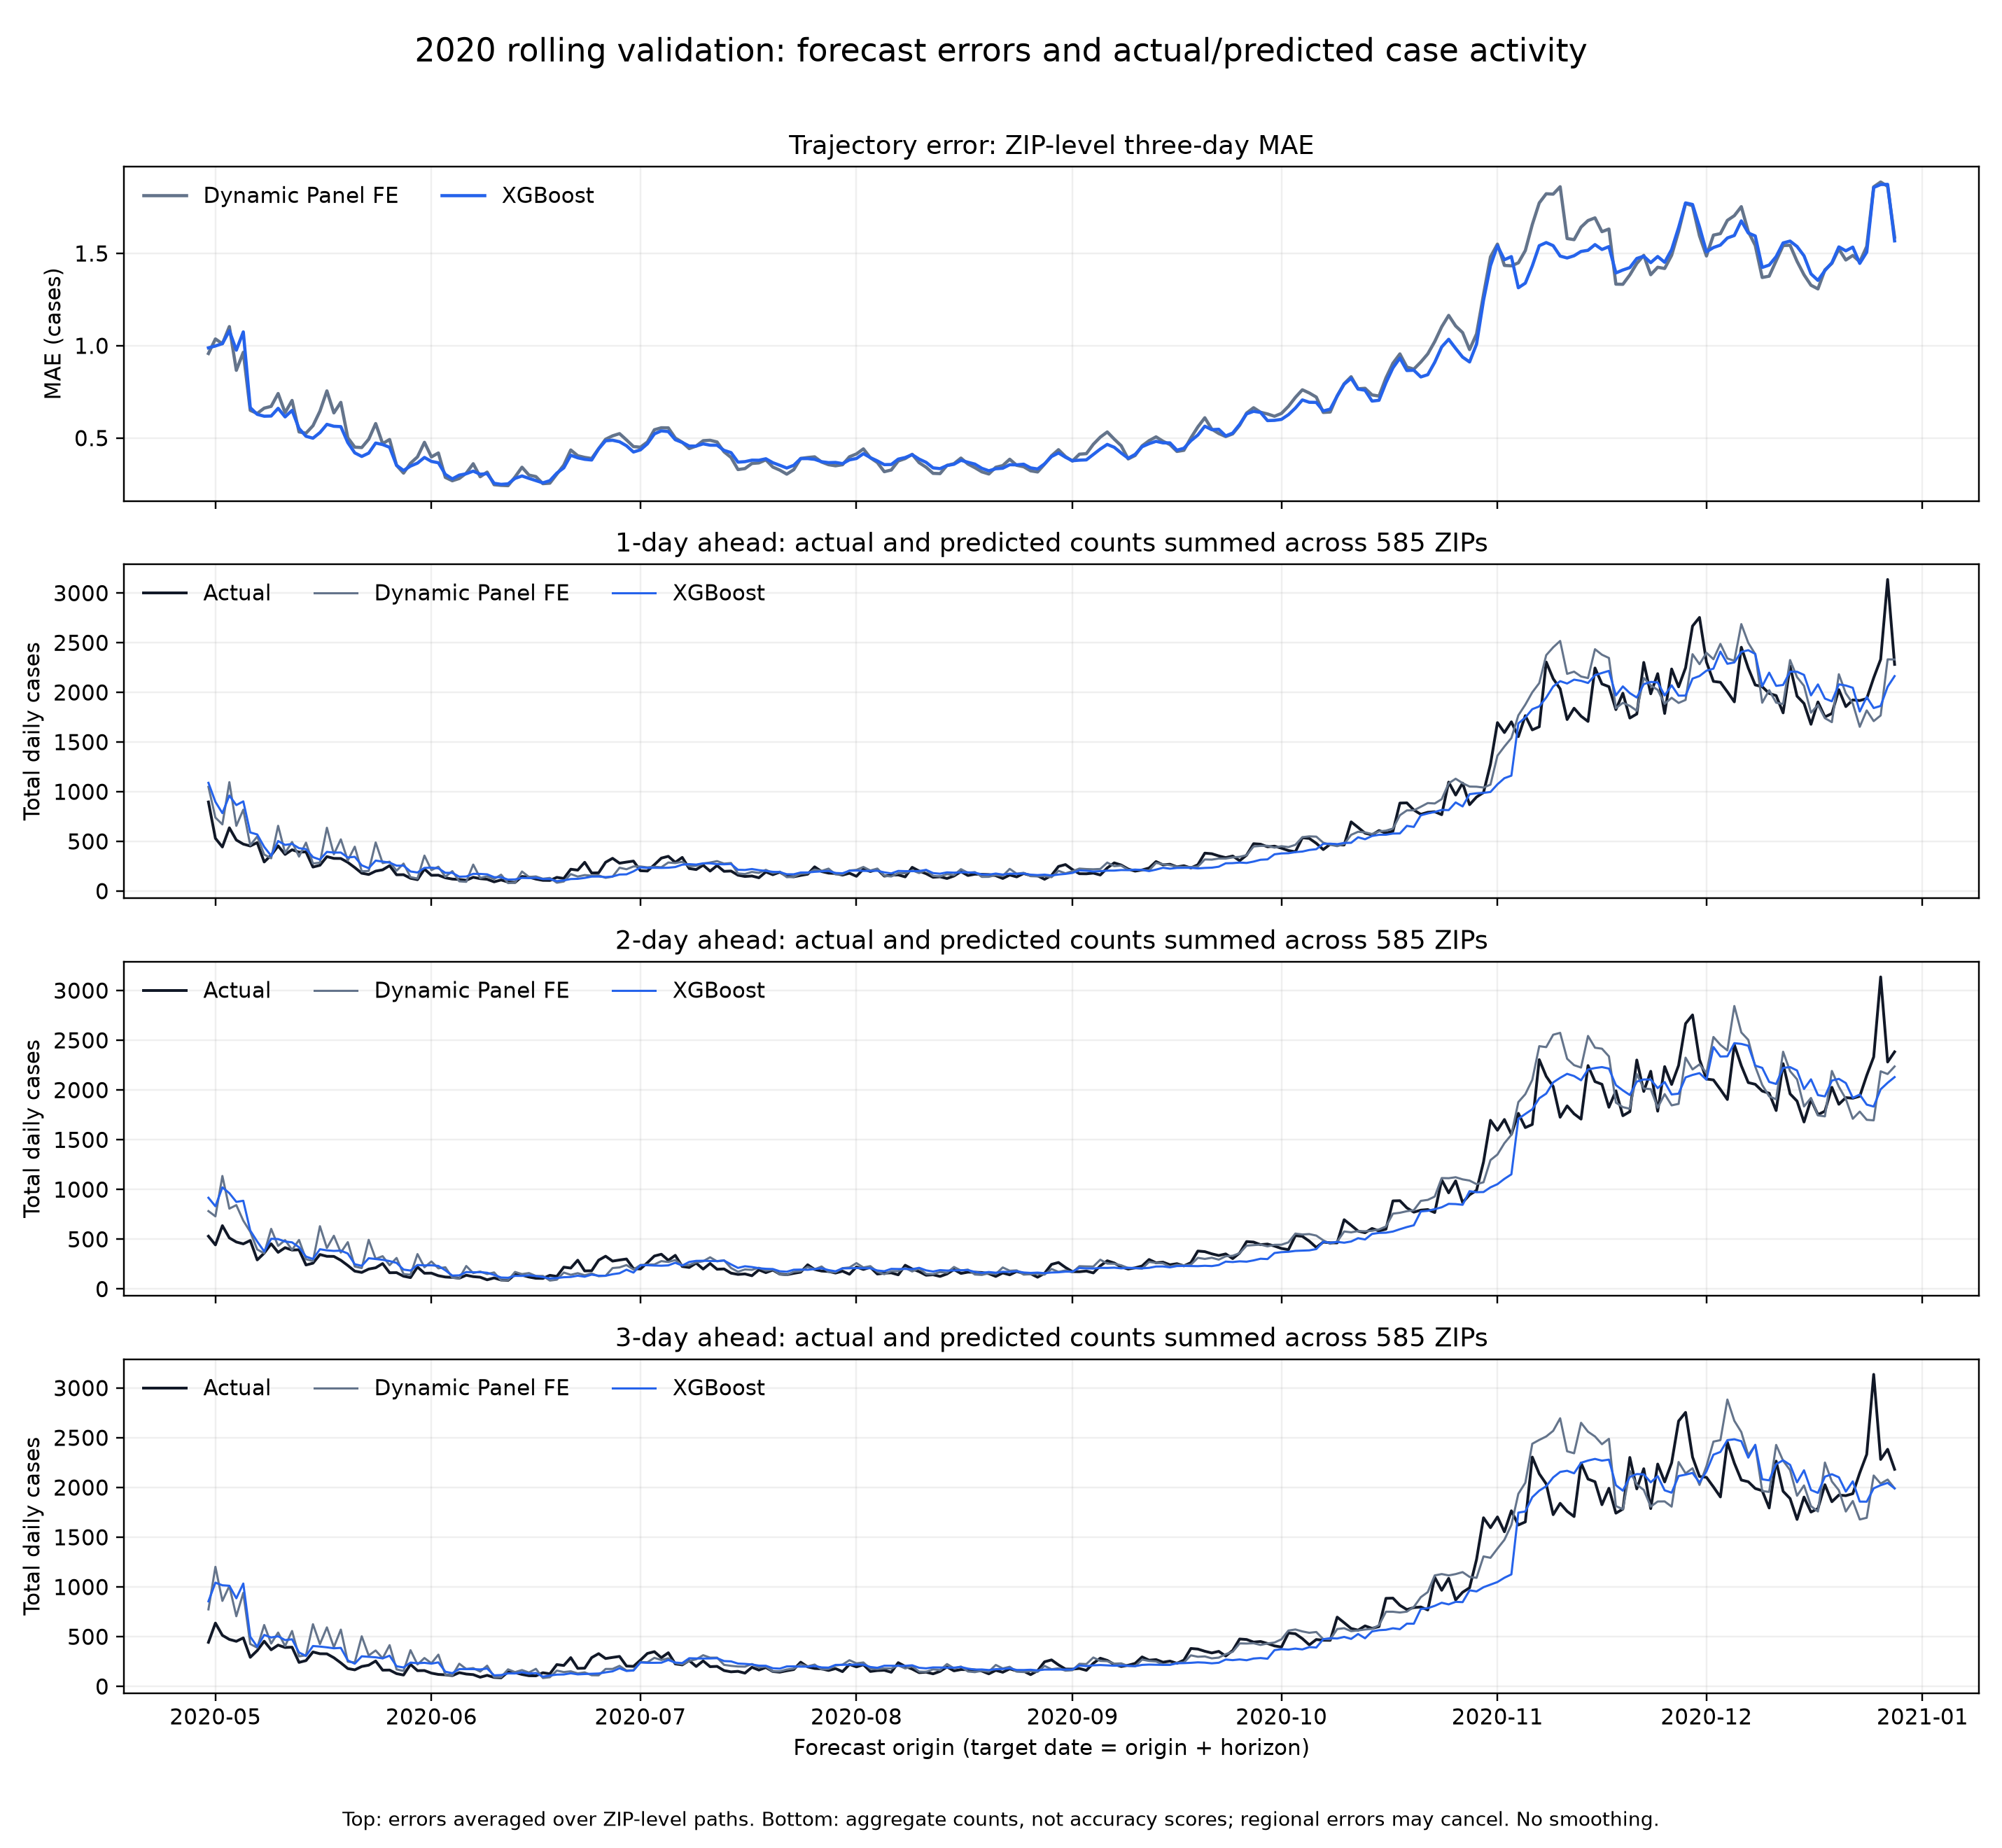

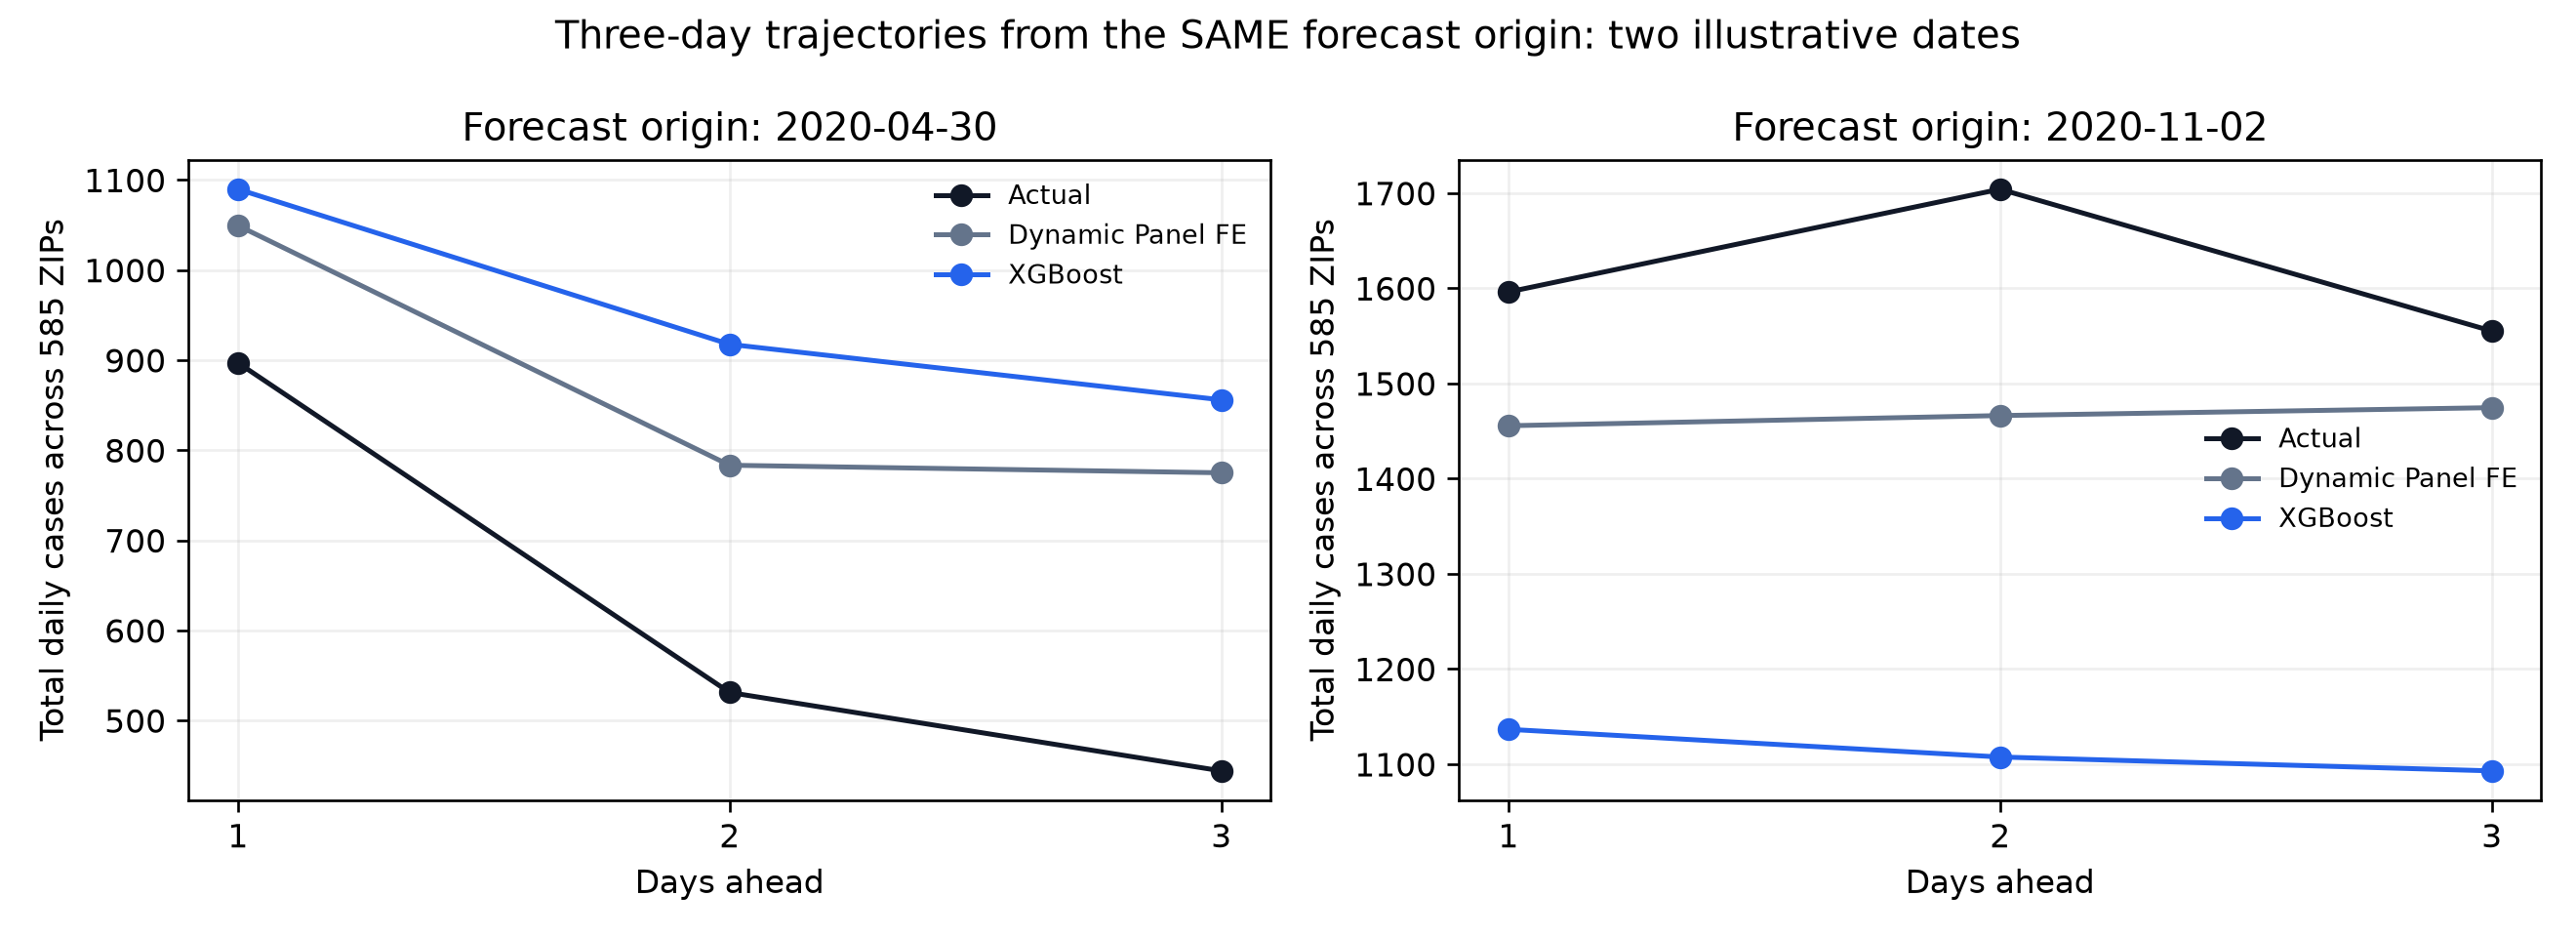

In [35]:
from IPython.display import Image,display
PLOT_ROOT=Path.cwd()
if not (PLOT_ROOT/'xgboost_trajectory_outputs').exists() and (PLOT_ROOT/'Weikun').is_dir():
    PLOT_ROOT=PLOT_ROOT/'Weikun'
PLOT_OUTPUT=PLOT_ROOT/'xgboost_trajectory_outputs'/'xgb60_weekly_development_20261027'/'comparison'
plot_actual_and_forecasts(PLOT_ROOT/'rolling_trajectory_outputs'/'rolling60_weekly_development_20261027'/'predictions.npz',PLOT_OUTPUT.parent/'predictions.npz',PLOT_OUTPUT)
display(Image(filename=str(PLOT_OUTPUT/'03_error_and_actual_forecasts.png')))
display(Image(filename=str(PLOT_OUTPUT/'04_actual_three_day_path_examples.png')))